# Atlas-DeePC: Joint-Sum Output Channels

Do the derived $\cos(q_1+q_2),\sin(q_1+q_2)$ channels help the **current baseline**?
This paired, noise-free study runs both methods afresh on **100 seeds, 211--310**.
These are previously used ablation seeds, not a new untouched evaluation set.

**Ten-output baseline:**
$$y_{10}=[\cos q_1,\cos q_2,\sin q_1,\sin q_2,
\dot q_1,\dot q_2,p_x,p_y,\cos(q_1+q_2),\sin(q_1+q_2)]^\top.$$
**Eight-output ablation:** $y_8=y_{10}[0:8]$.

The two channels are removed from **every offline Hankel block, online
measurement, clustering/localization feature, reference, and QP**. The 48-chart
atlas, graph, chart representatives, and rank-60 linear bases are rebuilt using
only the retained channels. The original offline episodes, inputs, and remaining
output samples are unchanged. No new offline trajectories are collected.

The retained outputs are not the literal raw environment observation vector:
as in the baseline, the absolute fingertip position is reconstructed from the
environment's relative fingertip-to-target observation and target coordinates.
The extra joint-sum trigonometric lift is what this experiment removes.

## 1. Fixed Control Setup

- Current baseline: rank-60 **linear subspace per chart**, iterative N=10
  terminal-reference candidates, graph waypoint references, current-chart DeePC.
- 48 physical-configuration charts, same MiniBatch K-means settings and seed.
  Clustering uses six trigonometric features in the baseline, four in the ablation;
  its input-history feature rows retain zero weight.
- $T_{\rm ini}=2$, prediction horizon 10, 320 control steps; input limits $[-1,1]$.
- $\lambda_g=0.05$, $\lambda_{\rm ini}=10^5$, $\lambda_{\Delta u}=5$, $R=10^{-4}I$;
  zero additional terminal cost, identical coefficient-bound construction.
- $Q_{10}=\operatorname{diag}(5000,5000,5000,5000,20,20,10^5,10^5,5000,5000)$;
  $Q_8=Q_{10}[0:8,0:8]$.
- Same 7 cm target-reference latch and 6 cm source-target separation rule.
- **No measurement noise**, contextual rescue, IK, fitted dynamics, or retuning.

Unlike the previous position-only-Q experiment, the retained posture and
velocity costs are still active. This tests removal of the lift throughout the
pipeline, not merely zeroing its tracking weights. It cannot isolate whether any
change arises from clustering, prediction, or the removed cost components.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/baseline_output_channels_ablation.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import baseline_output_channels_ablation as experiment
get_ipython().run_line_magic("matplotlib", "inline")
RUN_EXPERIMENTS = False
WORKERS = 4
if RUN_EXPERIMENTS:
    experiment.run_all(WORKERS)
RESULT_ROOT = experiment.RESULT_ROOT
payload = json.loads((RESULT_ROOT / "summary.json").read_text())
SEEDS = list(range(211, 311))
assert payload["version"] == experiment.VERSION and payload["seeds"] == SEEDS
LABELS = {"10": "10 outputs: baseline", "8": "8 outputs: no joint-sum lift"}
COLORS = {"10": "#0072B2", "8": "#D55E00"}
traces, records = {}, []
for dimension, panel in payload["panels"].items():
    assert [r["seed"] for r in panel["results"]] == SEEDS
    for row in panel["results"]:
        assert row["output_dimension"] == int(dimension)
        assert row["steps"] == 320 and row["candidate_count"] == 10
        assert row["matrix_geometry"] == "linear" and row["svd_rank"] == 60
        assert row["lam_g"] == .05 and row["q_dq"] == 20 and row["q_data_goal_joint"] == 5000
        path = RESULT_ROOT / f"output{dimension}" / f"seed{row['seed']}_control_results.npz"
        with np.load(path, allow_pickle=True) as trace:
            assert trace["y"].shape == trace["ref"].shape == (320, int(dimension))
            assert row["minimum_selected_goal_source_separation"] >= .06
            np.testing.assert_allclose(trace["distance"],
                np.linalg.norm(trace["y"][:, 6:8]-row["exact_target_xy"], axis=1))
            error = 1000*trace["distance"]
        traces[dimension, row["seed"]] = error
        records.append({**row, "dimension": dimension, "method": LABELS[dimension],
            "strict": experiment.strict_success(row), "mean_error_mm": 1000*row["mean_last_100"],
            "tail_within_10_pct": 100*np.mean(error[-100:] < 10),
            "ever_reached_10": bool(np.min(error) < 10)})
frame = pd.DataFrame(records)
for seed in SEEDS:
    pair = frame[frame.seed == seed]
    np.testing.assert_array_equal(pair.iloc[0].exact_target_xy, pair.iloc[1].exact_target_xy)
print("Verified 200 fresh rollouts: same 100 targets/seeds, retained-channel costs, full duration, and source-target separation.")
display(pd.Series({"offline seed range": payload["offline"]["fairness_audit"]["data_seed_range"],
    "stabilized offline episodes": payload["offline"]["fairness_audit"]["offline_stabilized_episode_count"],
    "10-output Hankel shape": payload["offline"]["hankel10_shape"],
    "8-output Hankel shape": payload["offline"]["hankel8_shape"],
    "new 8-output atlas fit time (s)": payload["offline"]["atlas8_fit_seconds"]}))


Verified 200 fresh rollouts: same 100 targets/seeds, retained-channel costs, full duration, and source-target separation.


offline seed range                 [2026, 2225]
stabilized offline episodes                   0
10-output Hankel shape             [144, 37800]
8-output Hankel shape              [120, 37800]
new 8-output atlas fit time (s)        0.094992
dtype: object

## 2. Paired Results

Strict success uses both final-30 and final-100 windows: mean fingertip error
below 10 mm and maximum below 20 mm. Briefly entering the target neighborhood is
reported separately and is not counted as stabilization. No rollout is truncated.


,Strict successes /100,Median final-100 mean (mm),P90 final-100 mean (mm),Ever below 10 mm /100,Mean final-100 time below 10 mm (%),Unsolved QPs
Method,,,,,,
10 outputs: baseline,93,2.062,5.426,94,93.0,0
8 outputs: no joint-sum lift,83,2.347,18.431,90,83.0,0


Repaired seeds                                     [232, 247, 252, 288, 299]
Regressed seeds            [231, 237, 241, 242, 243, 251, 253, 255, 262, ...
Net success change /100                                                  -10
dtype: object

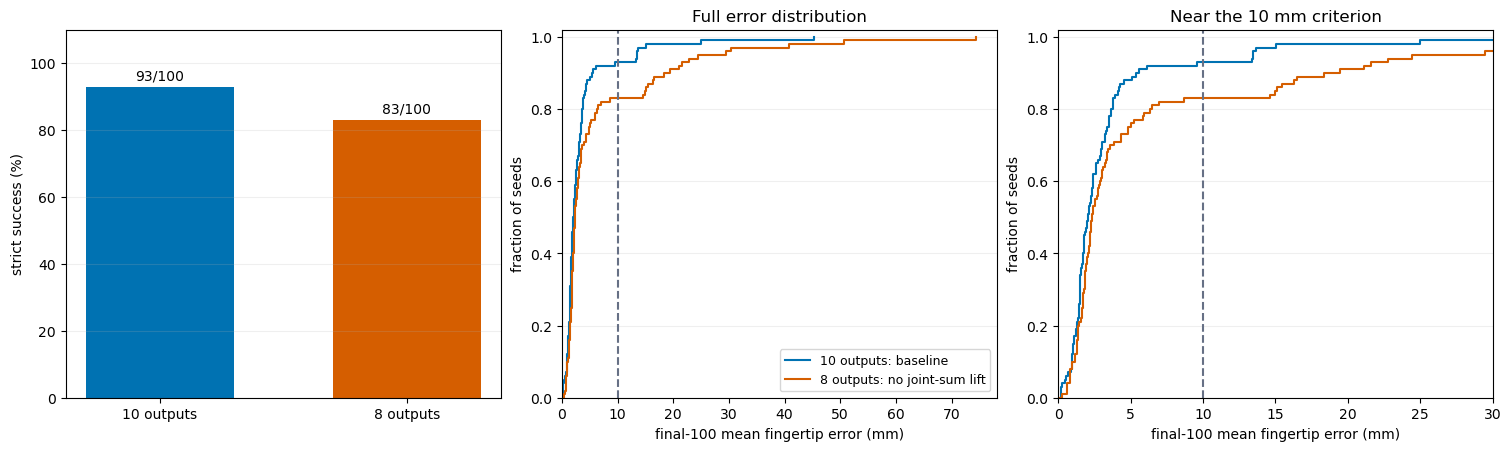

seed,method,strict,mean_error_mm,tail_within_10_pct
211,10 outputs: baseline,True,1.364,100.0
212,10 outputs: baseline,True,2.045,100.0
213,10 outputs: baseline,True,3.010,100.0
214,10 outputs: baseline,True,0.686,100.0
215,10 outputs: baseline,True,1.128,100.0
216,10 outputs: baseline,True,0.242,100.0
217,10 outputs: baseline,True,3.335,100.0
218,10 outputs: baseline,True,3.628,100.0
219,10 outputs: baseline,True,1.494,100.0
220,10 outputs: baseline,True,1.546,100.0


In [2]:
summary_rows = []
for dimension in ("10", "8"):
    rows = frame[frame.dimension == dimension]
    summary_rows.append({"Method": LABELS[dimension], "Strict successes /100": int(rows.strict.sum()),
        "Median final-100 mean (mm)": rows.mean_error_mm.median(),
        "P90 final-100 mean (mm)": rows.mean_error_mm.quantile(.9),
        "Ever below 10 mm /100": int(rows.ever_reached_10.sum()),
        "Mean final-100 time below 10 mm (%)": rows.tail_within_10_pct.mean(),
        "Unsolved QPs": int(rows.unsolved_steps.sum())})
summary = pd.DataFrame(summary_rows).set_index("Method")
display(summary.round(3))
paired = payload["paired"]
display(pd.Series({"Repaired seeds": paired["repaired"], "Regressed seeds": paired["regressed"],
    "Net success change /100": len(paired["repaired"])-len(paired["regressed"])}))
summary.to_json(RESULT_ROOT / "comparison_report.json", orient="index", indent=2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
for j, dimension in enumerate(("10", "8")):
    rows = frame[frame.dimension == dimension]
    success = int(rows.strict.sum())
    axes[0].bar(j, success, color=COLORS[dimension], width=.6)
    axes[0].text(j, success+2, f"{success}/100", ha="center")
    values = np.sort(rows.mean_error_mm)
    for ax in axes[1:]:
        ax.step(np.r_[0, values], np.r_[0, np.arange(1, 101)/100], where="post",
                color=COLORS[dimension], label=LABELS[dimension])
axes[0].set(xticks=[0, 1], xticklabels=["10 outputs", "8 outputs"], ylim=(0, 110), ylabel="strict success (%)")
for ax, title in zip(axes[1:], ["Full error distribution", "Near the 10 mm criterion"]):
    ax.axvline(10, color="#667085", linestyle="--")
    ax.set(ylim=(0, 1.02), xlim=(0, None), xlabel="final-100 mean fingertip error (mm)", ylabel="fraction of seeds", title=title)
axes[2].set_xlim(0, 30)
axes[1].legend(fontsize=9)
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.savefig(RESULT_ROOT / "output_channels_comparison.png", dpi=160)
plt.show()
display(HTML("<details><summary>All per-seed results</summary>" + frame[["seed", "method", "strict", "mean_error_mm", "tail_within_10_pct"]].round(3).to_html(index=False) + "</details>"))


## 3. Error Trajectories

Six fixed example seeds, full range followed by a 0--30 mm close-up. The 10 mm
line is the mean-error criterion, not the entire strict-success definition. Gray
shading indicates the final 100 steps. Off-scale samples in the close-up are
marked at the top; no smoothing or early stopping is applied.


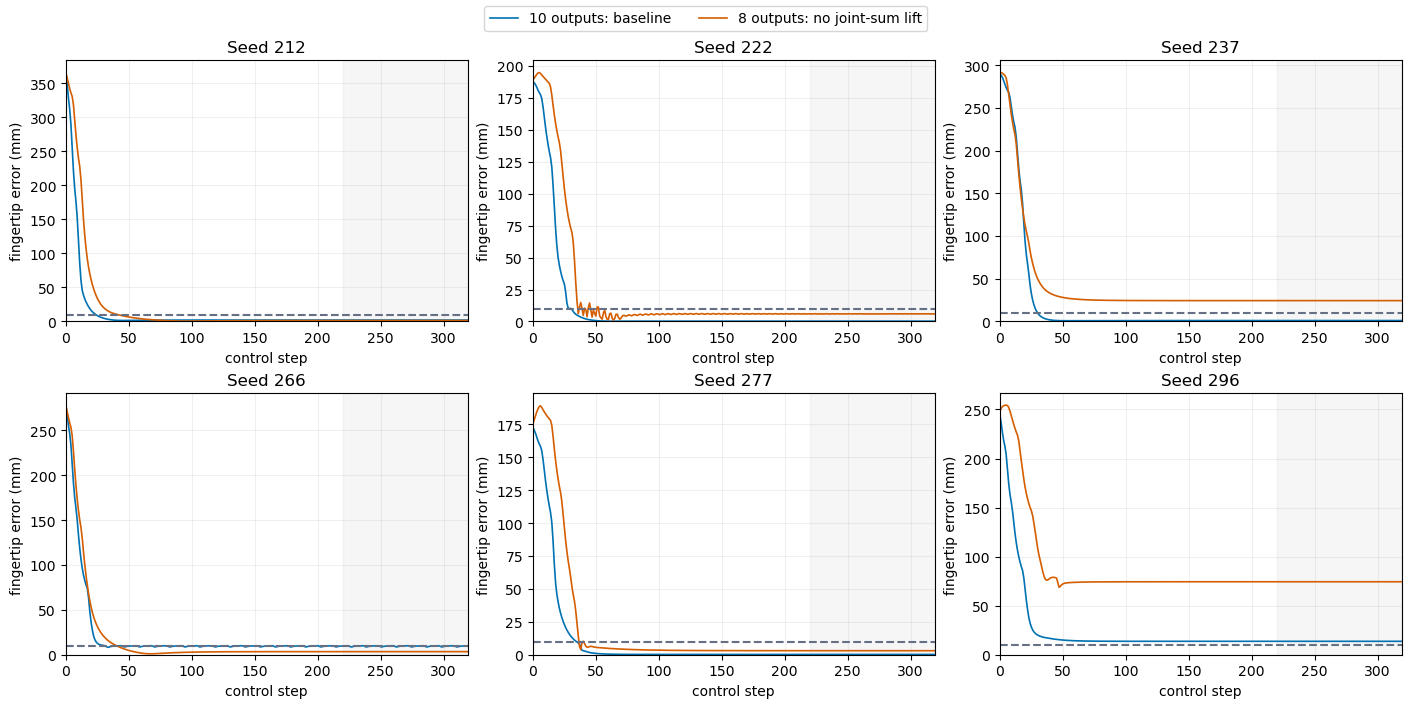

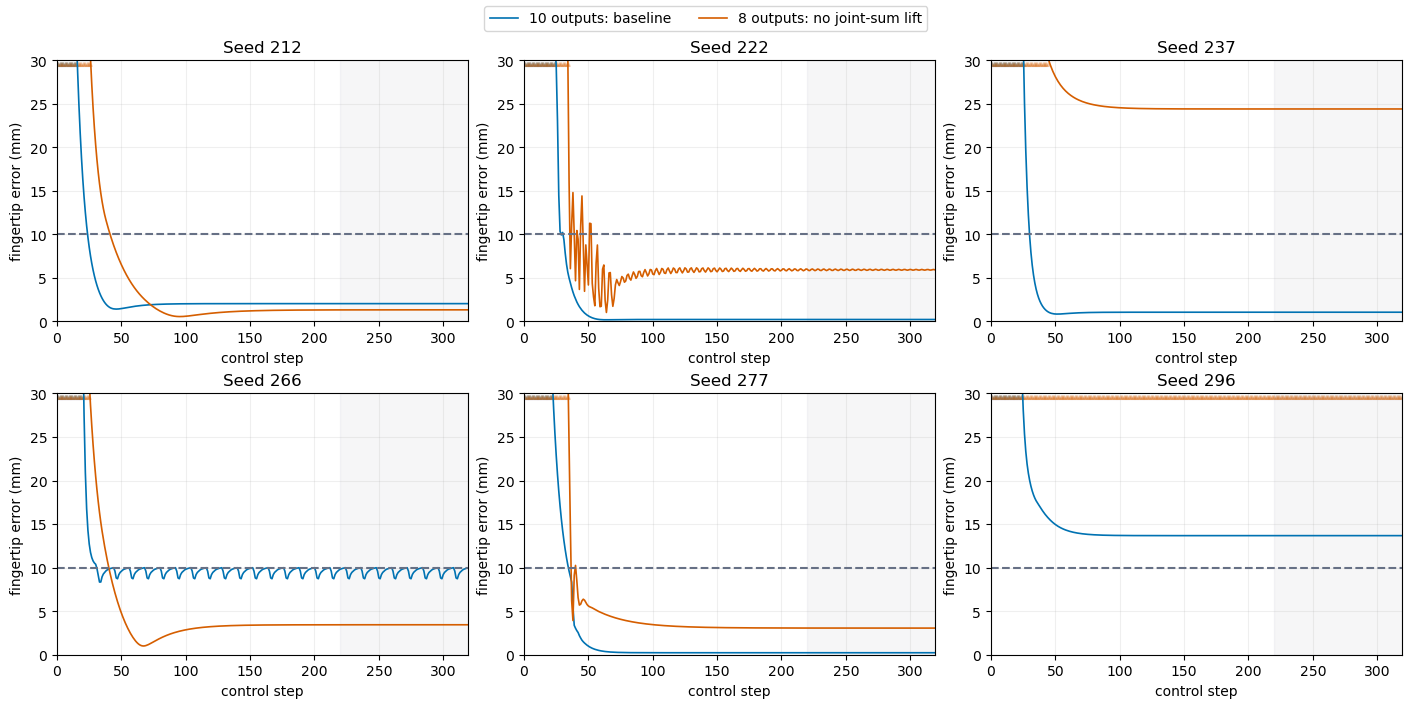

In [3]:
EXAMPLE_SEEDS = [212, 222, 237, 266, 277, 296]
for zoom in (False, True):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
    for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
        for dimension in ("10", "8"):
            error = traces[dimension, seed]
            ax.plot(error, color=COLORS[dimension], label=LABELS[dimension], linewidth=1.2)
            if zoom:
                outside = np.flatnonzero(error > 30)
                ax.scatter(outside, np.full(len(outside), 29.6), color=COLORS[dimension], marker="^", s=7, alpha=.2)
        ax.axvspan(220, 319, color="#667085", alpha=.06)
        ax.axhline(10, color="#667085", linestyle="--")
        ax.set(title=f"Seed {seed}", xlim=(0, 319), ylim=(0, 30) if zoom else (0, None),
               xlabel="control step", ylabel="fingertip error (mm)")
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2)
    suffix = "zoom" if zoom else "full"
    fig.savefig(RESULT_ROOT / f"output_channels_traces_{suffix}.png", dpi=160)
    plt.show()


## 4. Computation Time

Both methods were run afresh with four workers, one numerical-library thread per
worker, and alternating method order across seeds. Timings exclude the first five
control steps of each rollout. QP time includes construction and solve; simulator
stepping is excluded. These are shared-computer measurements, not isolated
real-time benchmarks. Offline SVD/chart preparation is outside online timers.


mean_ms  \
Method                       10 outputs: baseline   
module                                              
Chart localization                          0.093   
Graph routing                               0.009   
Linear subspace retrieval                   0.001   
Other control-loop work                     0.052   
QP construction and solve                  46.355   
Terminal-reference selection                0.022   
Total online control                       46.532   

                                                           \
Method                       8 outputs: no joint-sum lift   
module                                                      
Chart localization                                  0.074   
Graph routing                                       0.009   
Linear subspace retrieval                           0.001   
Other control-loop work                             0.051   
QP construction and solve                          45.175   
Terminal-reference selection                        0.022   
Total online control                               45.333   

                                        median_ms  \
Method                       10 outputs: baseline   
module                                              
Chart localization                          0.069   
Graph routing                               0.006   
Linear subspace retrieval                   0.001   
Other control-loop work                     0.036   
QP construction and solve                  41.110   
Terminal-reference selection                0.016   
Total online control                       41.274   

                                                           \
Method                       8 outputs: no joint-sum lift   
module                                                      
Chart localization                                  0.054   
Graph routing                                       0.006   
Linear subspace retrieval                           0.001   
Other control-loop work                             0.036   
QP construction and solve                          39.881   
Terminal-reference selection                        0.016   
Total online control                               40.028   

                                           p99_ms                               
Method                       10 outputs: baseline 8 outputs: no joint-sum lift  
module                                                                          
Chart localization                          0.504                        0.421  
Graph routing                               0.048                        0.050  
Linear subspace retrieval                   0.002                        0.002  
Other control-loop work                     0.283                        0.292  
QP construction and solve                 118.571                      118.771  
Terminal-reference selection                0.133                        0.135  
Total online control                      119.212                      118.936

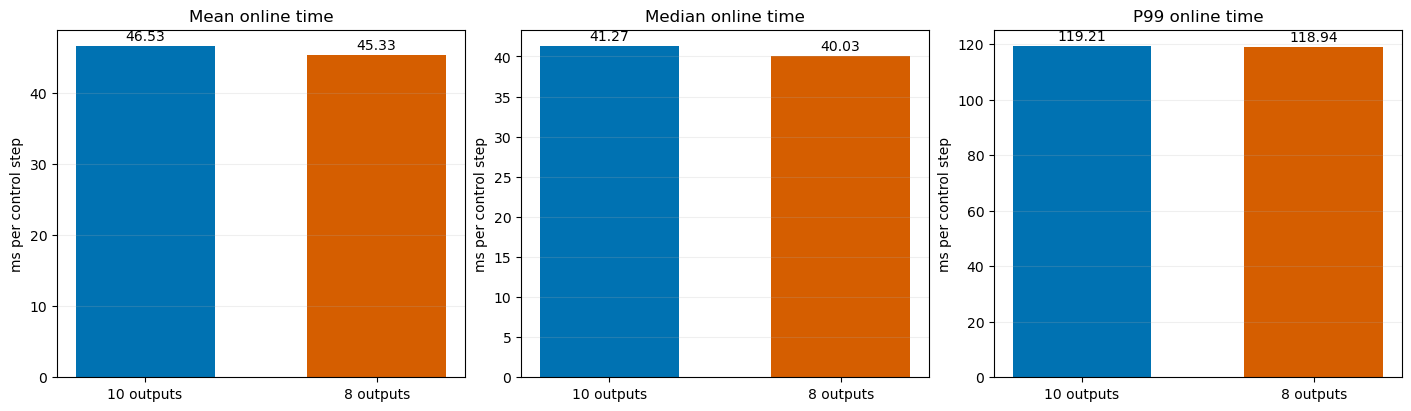

In [4]:
timing = pd.DataFrame([{"dimension": dimension, "Method": LABELS[dimension], **entry}
    for dimension, panel in payload["panels"].items() for entry in panel["timing"]["modules"]])
assert all(panel["timing"]["timed_steps"] == 31500 for panel in payload["panels"].values())
display(timing.pivot(index="module", columns="Method", values=["mean_ms", "median_ms", "p99_ms"]).round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, key, title in zip(axes, ["mean_ms", "median_ms", "p99_ms"], ["Mean online time", "Median online time", "P99 online time"]):
    for j, dimension in enumerate(("10", "8")):
        value = timing.loc[(timing.dimension == dimension) & (timing.module == "Total online control"), key].item()
        ax.bar(j, value, color=COLORS[dimension], width=.6)
        ax.annotate(f"{value:.2f}", (j, value), xytext=(0, 4), textcoords="offset points", ha="center")
    ax.set(xticks=[0, 1], xticklabels=["10 outputs", "8 outputs"], ylim=(0, None), ylabel="ms per control step", title=title)
    ax.margins(y=.15)
    ax.grid(axis="y", alpha=.2)
fig.savefig(RESULT_ROOT / "output_channels_timing.png", dpi=160)
plt.show()


## Interpretation and Reproduction

The joint-sum channels are deterministic functions of the individual joint
cosines and sines. They add no independent noise-free state information, but can
change the geometry of clustering and the effectiveness of a finite-rank linear
behavioral representation. Therefore information redundancy does not imply that
removing the channels leaves this controller numerically unchanged.

This is an end-to-end output-lifting ablation. Both the chart memberships and
the graph/reference sequence may change. The number of coefficient variables
remains 60; the behavioral rows decrease from 144 to 120. No conclusion about
the separate effect of lifting on clustering versus prediction is claimed.

```bash
python src/baseline_output_channels_ablation.py --workers 4
```

The notebook defaults to displaying saved results. Existing baseline notebooks,
the older eight-output study, and the noisy-control ablations are unchanged.
